In [2]:
import torch
import pandas as pd
import numpy as np

import random

In [6]:
df = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df

,oriTDB_accession,oriTDB_id,nic site,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,sDBM_sim_gap,oriT_nic_seq
0,100001,GAATAAGGGACAGTGAAGAAGGAACACCCGCTCGCGGGTGGGCCTA...,60..61,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
1,100002,CCGGCCAGCCTCGCAGAGCAGGATTCCCGTTGAGCACCGCCAGGTG...,107..108,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Klebsiella aerogenes K8841,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
2,100003,CCAGTTTCTCGAAGAGAAACCGGTAAGTGCGCCCTCCC,31..32,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)",16.299099,AAGTGCGCC
3,100004,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
4,100005,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
...,...,...,...,...,...,...,...,...,...,...
1391,104307,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 12379-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1392,104309,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter asburiae strain 16773-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1393,104312,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 11743-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1394,104313,TATTTCATTTTTTGTTTTTTTAATCAGTTAGTTAGTGCGATTCATC...,62..63,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,Enterobacter kobei strain 11743-yvys,SKDSSFTAW,"(27, 35)",0.767967,TAGGTGTAT


In [7]:
df = df.dropna(subset=['oriT_nic_seq'])

# remember to set sDBM threshold

df = df.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'host', 'sDBM_sim_gap'])

df = df.drop_duplicates(subset=["sDBM", "oriT_nic_seq", "relaxase_sequence"], keep='first')

df

,relaxase_family,relaxase_sequence,sDBM,sDBM_pos,oriT_nic_seq
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,HLTAKTGSR,"(4, 12)",AAGTGCGCC
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA
5,TraA,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...,IAKRENGKR,"(2, 10)",AAGTGCGCC
6,TraI,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...,SISSIKGDA,"(2, 10)",CGGGTGTGG
...,...,...,...,...,...
1379,Rep_trans_F1621_RS12210_SESURV_p2,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...,TIVGNLNKN,"(24, 32)",TCGATTGGT
1381,MobH,MNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGDQK...,RALYLCIKR,"(3, 11)",AGTTTGGTT
1384,traI_EPE00_RS00720,MMSIAQVRSAGSAGNYYTDKDNYYVLGSMGERWAGRGAEQLRLQGS...,SIAQVRSAG,"(2, 10)",GGGGTGTGG
1389,MobQ,MAIYHLSMKIISRKNGYSAVASAAYRSGSVIPDDRTGLIHDYTRKR...,HLSMKIISR,"(4, 12)",GAACTGGCA


In [8]:
# New run - Combine Rep and relaxase

df_new_relaxase = pd.read_csv("../data/processed/unique_relaxase_oriT_dataset.csv")

df_new_rep = pd.read_csv("../data/processed/unique_rep_oriR_dataset.csv")


df_new_rep.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "ori_seq": "ori_nic_seq", "rep_amino_acid_seq": "amino_acid_seq"}, inplace=True)
df_new_relaxase.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "oriT_nic_seq": "ori_nic_seq", "relaxase_sequence": "amino_acid_seq"}, inplace=True)

df = pd.concat([df_new_relaxase, df_new_rep], ignore_index=True)

df

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
1,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
2,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
3,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
4,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
422,"(88, 96)",HPNIQGAKS,TAAAAATAC,MPRAGRFSIKAKNYFLTYPQCSLSKEEALSQLQNLITPTNKKYIKI...
423,"(88, 96)",HPNIQGAKS,TACTAATAC,MPPPNKFRINAKNYFLTYPRCSLTKEEALSQIKALETPISKLFIRI...
424,"(88, 96)",HPNVQGAKS,TTATACTAC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...
425,"(88, 96)",HPNIQGAKS,TTATCCTAC,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...


In [9]:
negative_df = df.copy()

def shuffle_until_no_match(max_attempts=10000):

    minMatches = np.inf
    best_shuffle = None
    best_shuffle_same_ori_rows = None

    for _ in range(max_attempts):
        negative_df['ori_nic_seq'] = np.random.permutation(negative_df['ori_nic_seq'])

        boolarr = negative_df['ori_nic_seq'].values == df['ori_nic_seq'].values

        if not np.any(boolarr):
            print("Perfect shuffle")
            return negative_df.copy(), None, None

        if boolarr.sum() < minMatches:
            minMatches = boolarr.sum()
            best_shuffle_same_ori_rows = np.where(boolarr)[0]
            best_shuffle = negative_df.copy()

    
    print(best_shuffle_same_ori_rows)


    print("Failed")

    print(minMatches)

    return best_shuffle, best_shuffle_same_ori_rows, minMatches


best_negative_df, indices, minMatches = shuffle_until_no_match()


def mutate_ori_dataset(df, rows):

    bases = np.array(['A', 'C', 'T', 'G'])


    for row in rows:
        row = int(row)

        same_ori = df.iloc[row]['ori_nic_seq']
        
        random_pos = random.randint(0, len(same_ori) - 1)

        current_base = same_ori[random_pos]

        possible_bases = bases[bases != current_base]
        random_base = random.choice(possible_bases)

        mutated_ori = (
            same_ori[:random_pos]
            + random_base
            + same_ori[random_pos + 1:]
        )

        mutated_ori = same_ori[:random_pos] + random_base + same_ori[random_pos + 1:]
        print(same_ori)
        print(mutated_ori)

        df.iloc[row, df.columns.get_loc('ori_nic_seq')] = mutated_ori


mutate_ori_dataset(best_negative_df,indices)


if(np.any(best_negative_df['ori_nic_seq'].values == df['ori_nic_seq'].values)):
    print("Negative dataset has contradictions")
else:
    print("Success! All ori are different!")


df['match'] = "Yes"
best_negative_df['match'] = "No"


final_df = pd.concat([df, best_negative_df], ignore_index=True)

final_df

[233]
Failed
1
TAGTATTAC
TAGGATTAC
Success! All ori are different!


,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq,match
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Yes
1,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Yes
2,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,Yes
3,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...,Yes
4,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...,Yes
...,...,...,...,...,...
849,"(88, 96)",HPNIQGAKS,TAATGTTAC,MPRAGRFSIKAKNYFLTYPQCSLSKEEALSQLQNLITPTNKKYIKI...,No
850,"(88, 96)",HPNIQGAKS,TGATATTAC,MPPPNKFRINAKNYFLTYPRCSLTKEEALSQIKALETPISKLFIRI...,No
851,"(88, 96)",HPNVQGAKS,TACCCTGTC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...,No
852,"(88, 96)",HPNIQGAKS,AACTATTAC,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...,No


In [1]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()


ESMC: Transformer Engine is not installed; falling back to pure-PyTorch LayerNorm+Linear / LayerNorm+MLP. Outputs will differ numerically - measured on the unnormalized residual stream (before the final LayerNorm), ~O(10) max-diff in fp32 and ~O(100) in bf16; after the final LayerNorm these shrink to a few ULP and perplexity stays within rounding noise. Install with `pip install transformer-engine[pytorch]` to enable fused fp32-reduction LayerNorm.
ESMC: neither xformers nor flash-attn is installed; falling back to PyTorch ``F.scaled_dot_product_attention``. The attention reduction order in bf16 differs from a fused kernel by ~1 bf16 ULP per attention block; compounded across the 80-block stack this reaches ~O(100) max-diff on the unnormalized residual stream. Install an xformers build matching your PyTorch and CUDA versions for a fused attention kernel.
ESMC: flash-attn rotary kernel not installed; falling back to pure-PyTorch RoPE. For faster GPU inference run `pip install flash-attn

NameError: name 'torch' is not defined

In [11]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [12]:
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import random

pca1 = PCA()

In [13]:
sDBM_tensor_list = []

ori_tensor_list = []


for index, row in final_df.iterrows():
    sDBM_start, sDBM_end = ast.literal_eval(row.values[0])
    sDBM_end += 1

    ori_seq = row.values[2]
    amino_seq = row.values[3]

    sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    sDBM_tensor_list.append(sDBM_embedding.cpu())
    ori_tensor_list.append(ori_one_hot)


embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(embedding_tensor.shape)
print(ori_one_hot_tensor.shape)

torch.Size([854, 9, 960])
torch.Size([854, 9, 4])


In [53]:
# only run if previous cell hasnt been run already!


ori_tensor_list = []


for index, row in final_df.iterrows():

    ori_seq = row.values[4]

    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    ori_tensor_list.append(ori_one_hot)


ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(ori_one_hot_tensor.shape)

torch.Size([1292, 9, 4])


In [15]:
embedding_tensor.shape

torch.Size([854, 9, 960])

In [39]:
pca2 = PCA(0.80)


embed_np = embedding_tensor.cpu().numpy()


reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)



binary_target_list = []


for index, row in final_df.iterrows():

    match_str = row.values[4]

    if match_str == 'Yes':
        binary_target_list.append(1)
    else:
        binary_target_list.append(0)


targets_tensor = torch.tensor(binary_target_list, dtype = torch.long)


print(targets_tensor.shape)

(854, 41)
(854, 36)
(854, 43)
(854, 43)
(854, 49)
(854, 43)
(854, 48)
(854, 46)
(854, 48)
torch.Size([854, 397])
torch.Size([854])


In [40]:
# Append into single input vector

X = torch.cat((sDBM_embedding, ori_one_hot), dim = 1)
print(X.shape)
y = targets_tensor
print(y.shape)


torch.save(X, "../data/embeddings/X_input_vectors.pt")
torch.save(y, "../data/embeddings/y_target_labels.pt")


torch.save(embedding_tensor, "../data/embeddings/full_sDBM_embeddings.pt")

torch.Size([854, 433])
torch.Size([854])


In [18]:
from pathlib import Path
import torch

tensor_dir = Path(r"../data/embeddings/classifier_combined/")

X_train = torch.load(tensor_dir / "X_train.pt", weights_only=True)
y_train = torch.load(tensor_dir / "y_train.pt", weights_only=True)
X_val_rep = torch.load(tensor_dir / "X_val_rep.pt", weights_only=True)
y_val_rep = torch.load(tensor_dir / "y_val_rep.pt", weights_only=True)
X_val_relax = torch.load(tensor_dir / "X_val_relax.pt", weights_only=True)
y_val_relax = torch.load(tensor_dir / "y_val_relax.pt", weights_only=True)

print(X_train.shape)

torch.Size([710, 34])


In [19]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


full_dataset = CustomDataset(X_train, y_train)

/tmp/ipykernel_927/947132182.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_927/947132182.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.float32)


In [20]:
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


count_p = 0

for row in train_dataset:
    if row[1] == 1:
        count_p += 1

print(f"(Train) Positive: {count_p}")
print(f"(Train) Negative: {len(train_dataset) - count_p}")


count = 0

for row in test_dataset:
    if row[1] == 1:
        count += 1

print(f"(Test) Positive: {count}")
print(f"(Test) Negative: {len(test_dataset) - count}")

x_test_dataset = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
y_test_dataset = torch.tensor([test_dataset[i][1] for i in range(len(test_dataset))])

train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

(Train) Positive: 280
(Train) Negative: 288
(Test) Positive: 75
(Test) Negative: 67


In [21]:
train_dataloader = DataLoader(dataset=full_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

### Machine Learning

In [22]:
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [8]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
  #      x = self.dropout(x)
        return self.fc2(x)

In [23]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2)
        self.fc3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

In [46]:
import torch
import torch.nn as nn


class BinaryClassifierTwoHeadNN(nn.Module):
    def __init__(
        self,
        sdbm_dim,
        dna_dim=9,
        hidden_dim1=32,
        head_dim=24,
        dropout_p=0.2,
    ):
        # Initialise the nn.Module parent class.
        super().__init__()

        # sDBM protein embedding head
        self.sdbm_fc = nn.Linear(sdbm_dim, head_dim)

        # DNA encoding head
        self.dna_fc = nn.Linear(dna_dim, head_dim)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_p)

        # Shared layers after combining the two heads
        self.fc1 = nn.Linear(head_dim * 2, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, 1)

    def forward(self, sdbm_input, dna_input):
        sdbm = self.dropout(self.relu(self.sdbm_fc(sdbm_input)))
        dna = self.dropout(self.relu(self.dna_fc(dna_input)))

        # Join the learned representations from both input heads.
        x = torch.cat((sdbm, dna), dim=1)

        x = self.dropout(self.relu(self.fc1(x)))

        # Return logits; pass them directly to BCEWithLogitsLoss.
        return self.fc2(x)

In [24]:
#protein_dna_bind_classifier = BinaryClassiferNN(53,32).to(device)
protein_dna_bind_classifier = BinaryClassiferNN(34, 48, 32).to(device) #32, 16 -> 0.30
#protein_dna_bind_classifier = BinaryClassiferNN(410, 92, 64).to(device)

#protein_dna_bind_classifier = BinaryClassifierTwoHeadNN(127).to(device)

protein_dna_bind_classifier.state_dict() # random parameters before training
next(protein_dna_bind_classifier.parameters()).device

# set up the loss function
loss_fn = nn.BCEWithLogitsLoss() #interally applies sigmoid

optimiser = torch.optim.Adam(protein_dna_bind_classifier.parameters(), lr=0.001)

def accuracy_fn(y_true, y_pred):
    correct_pred = torch.eq(y_true, y_pred).sum().item()

    accuracy = (correct_pred/len(y_pred)) * 100

    return accuracy

In [25]:
# Combine rep and relaxase validation sets.
x_test_dataset = torch.cat((X_val_rep, X_val_relax), dim=0)
y_test_dataset = torch.cat((y_val_rep, y_val_relax), dim=0)

torch.manual_seed(3242)

epochs = 100
acc = []
acc_val = []

loss_train = []
loss_val = []

for epoch in range(epochs):
    protein_dna_bind_classifier.train()
    running_loss = 0.0
    running_acc = 0.0

    for inputs, targets in train_dataloader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).float().unsqueeze(dim=1)

        y_logits = protein_dna_bind_classifier(inputs)
        y_pred = torch.round(torch.sigmoid(y_logits))

        accuracy = accuracy_fn(targets, y_pred)
        loss = loss_fn(y_logits, targets)

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        running_loss += loss.item()
        running_acc += accuracy.item() if torch.is_tensor(accuracy) else accuracy

    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)

    protein_dna_bind_classifier.eval()

    with torch.inference_mode():
        test_inputs = x_test_dataset.to(device, non_blocking=True)
        test_targets = (
            y_test_dataset.to(device, non_blocking=True)
            .float()
            .unsqueeze(dim=1)
        )

        test_logits = protein_dna_bind_classifier(test_inputs)
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)
        test_accuracy = accuracy_fn(test_targets, test_pred)

    acc.append(epoch_acc)
    acc_val.append(
        test_accuracy.item() if torch.is_tensor(test_accuracy) else test_accuracy
    )

    # After calculating epoch_loss and test_loss:
    loss_train.append(epoch_loss)
    loss_val.append(test_loss.item())

    print(
        f"Epoch: {epoch + 1:02d}/{epochs} | "
        f"Training Loss: {epoch_loss:.4f} | "
        f"Training Accuracy: {epoch_acc:.4f} | "
        f"Validation Loss: {test_loss.item():.4f} | "
        f"Validation Accuracy: {acc_val[-1]:.4f}"
    )

Epoch: 01/100 | Training Loss: 0.7801 | Training Accuracy: 52.0380 | Validation Loss: 0.7118 | Validation Accuracy: 52.8090
Epoch: 02/100 | Training Loss: 0.7408 | Training Accuracy: 49.4565 | Validation Loss: 0.6994 | Validation Accuracy: 47.1910
Epoch: 03/100 | Training Loss: 0.7412 | Training Accuracy: 47.5996 | Validation Loss: 0.6991 | Validation Accuracy: 48.3146
Epoch: 04/100 | Training Loss: 0.7259 | Training Accuracy: 49.2754 | Validation Loss: 0.7027 | Validation Accuracy: 48.3146
Epoch: 05/100 | Training Loss: 0.7178 | Training Accuracy: 49.3207 | Validation Loss: 0.6982 | Validation Accuracy: 48.3146
Epoch: 06/100 | Training Loss: 0.7050 | Training Accuracy: 52.0380 | Validation Loss: 0.6973 | Validation Accuracy: 44.9438
Epoch: 07/100 | Training Loss: 0.7012 | Training Accuracy: 50.6341 | Validation Loss: 0.6988 | Validation Accuracy: 48.8764
Epoch: 08/100 | Training Loss: 0.7077 | Training Accuracy: 48.7772 | Validation Loss: 0.6966 | Validation Accuracy: 48.3146
Epoch: 0

In [50]:
DNA_DIM = 9

# Combine rep and relaxase validation sets.
x_test_dataset = torch.cat((X_val_rep, X_val_relax), dim=0)
y_test_dataset = torch.cat((y_val_rep, y_val_relax), dim=0)

torch.manual_seed(3242)

epochs = 100
acc = []
acc_val = []
loss_train = []
loss_val = []

for epoch in range(epochs):
    protein_dna_bind_classifier.train()
    running_loss = 0.0
    running_acc = 0.0

    for inputs, targets in train_dataloader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).float().unsqueeze(dim=1)

        # Protein embedding is everything except the final 36 DNA features.
        sdbm_input = inputs[:, :-DNA_DIM]
        dna_input = inputs[:, -DNA_DIM:]

        y_logits = protein_dna_bind_classifier(sdbm_input, dna_input)
        y_pred = torch.round(torch.sigmoid(y_logits))

        accuracy = accuracy_fn(targets, y_pred)
        loss = loss_fn(y_logits, targets)

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        running_loss += loss.item()
        running_acc += accuracy.item() if torch.is_tensor(accuracy) else accuracy

    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)

    protein_dna_bind_classifier.eval()

    with torch.inference_mode():
        test_inputs = x_test_dataset.to(device, non_blocking=True)
        test_targets = (
            y_test_dataset.to(device, non_blocking=True)
            .float()
            .unsqueeze(dim=1)
        )

        test_sdbm_input = test_inputs[:, :-DNA_DIM]
        test_dna_input = test_inputs[:, -DNA_DIM:]

        test_logits = protein_dna_bind_classifier(
            test_sdbm_input,
            test_dna_input,
        )
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)
        test_accuracy = accuracy_fn(test_targets, test_pred)

    acc.append(epoch_acc)
    acc_val.append(
        test_accuracy.item() if torch.is_tensor(test_accuracy) else test_accuracy
    )
    loss_train.append(epoch_loss)
    loss_val.append(test_loss.item())

    print(
        f"Epoch: {epoch + 1:02d}/{epochs} | "
        f"Training Loss: {epoch_loss:.4f} | "
        f"Training Accuracy: {epoch_acc:.4f} | "
        f"Validation Loss: {test_loss.item():.4f} | "
        f"Validation Accuracy: {acc_val[-1]:.4f}"
    )

Epoch: 01/100 | Training Loss: 0.7240 | Training Accuracy: 49.0057 | Validation Loss: 0.7026 | Validation Accuracy: 47.7528
Epoch: 02/100 | Training Loss: 0.6984 | Training Accuracy: 50.8523 | Validation Loss: 0.7067 | Validation Accuracy: 47.1910
Epoch: 03/100 | Training Loss: 0.7018 | Training Accuracy: 50.9943 | Validation Loss: 0.7057 | Validation Accuracy: 46.6292
Epoch: 04/100 | Training Loss: 0.6934 | Training Accuracy: 52.4148 | Validation Loss: 0.7105 | Validation Accuracy: 42.1348
Epoch: 05/100 | Training Loss: 0.6880 | Training Accuracy: 53.2670 | Validation Loss: 0.7104 | Validation Accuracy: 45.5056
Epoch: 06/100 | Training Loss: 0.6774 | Training Accuracy: 56.3920 | Validation Loss: 0.7144 | Validation Accuracy: 45.5056
Epoch: 07/100 | Training Loss: 0.6732 | Training Accuracy: 60.3693 | Validation Loss: 0.7121 | Validation Accuracy: 45.5056
Epoch: 08/100 | Training Loss: 0.6765 | Training Accuracy: 57.3864 | Validation Loss: 0.7082 | Validation Accuracy: 46.6292
Epoch: 0

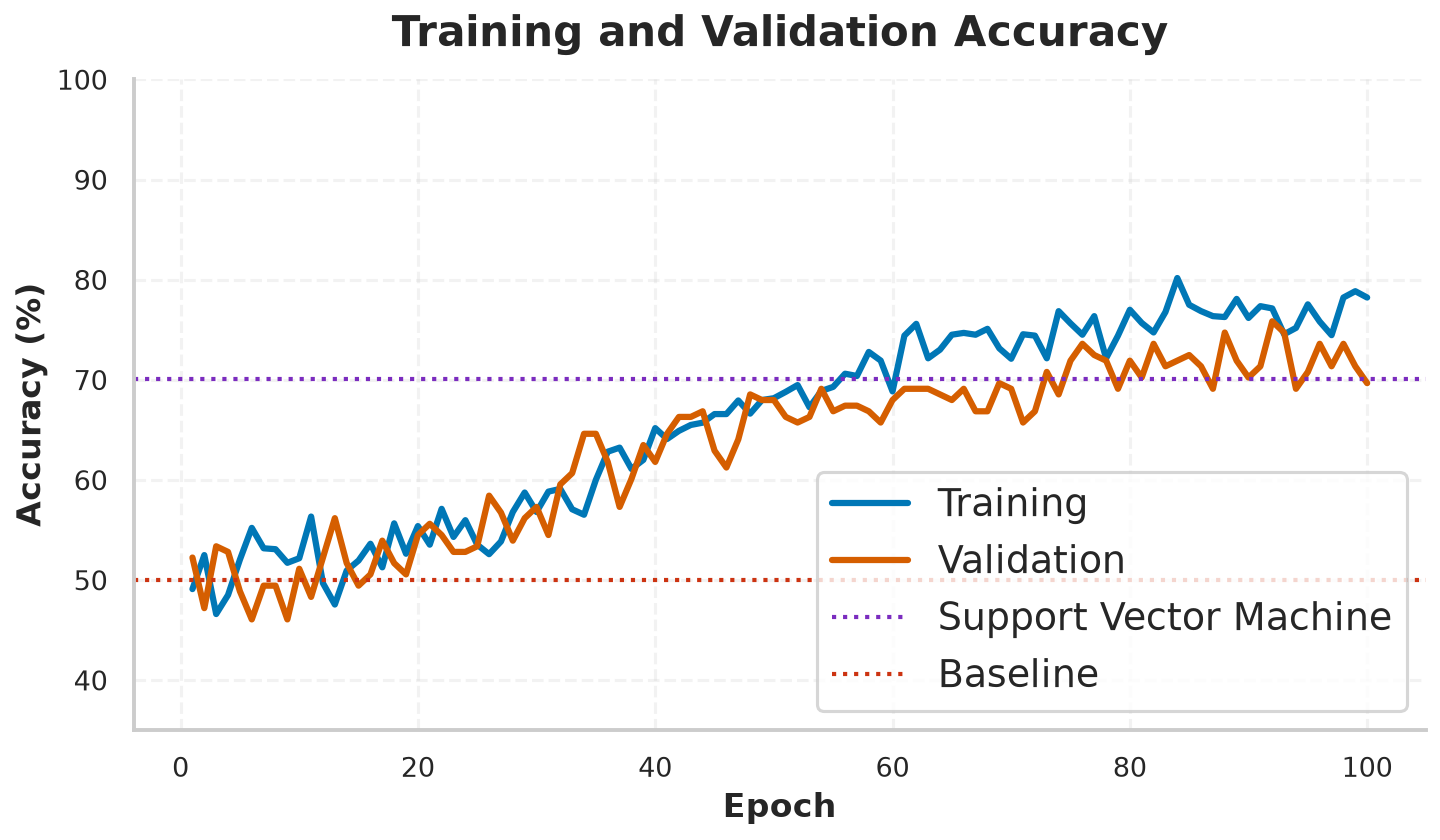

In [14]:
# previous run -> before reverting the accidental pull

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert fractions to percentages. Remove * 100 if your values are already percentages.
plot_data = pd.DataFrame({
    "Epoch": list(range(1, len(acc) + 1)) * 2,
    "Accuracy": [value for value in acc + acc_val],
    "Dataset": (
        ["Training"] * len(acc)
        + ["Validation"] * len(acc_val)
    ),
})

sns.set_theme(
    style="whitegrid",
    context="talk",
    font_scale=1.1,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.lineplot(
    data=plot_data,
    x="Epoch",
    y="Accuracy",
    hue="Dataset",
    hue_order=["Training", "Validation"],
    palette={"Training": "#0077B6", "Validation": "#D55E00"},
    linewidth=3,
    ax=ax,
)

# ax.axhline(
#     y=76.3,
#     color="#CC3311",
#     linestyle=":",
#     linewidth=2,
#     label="Random Forest",
# )

ax.axhline(
    y=70.1,
    color="#7B2CBF",
    linestyle=":",
    linewidth=2,
    label="Support Vector Machine",
)


ax.axhline(
    y=50.0,
    color="#CC3311",
    linestyle=":",
    linewidth=2,
    label="Baseline",
)

ax.set_title("Training and Validation Accuracy", pad=16, fontsize=20)
ax.set_xlabel("Epoch", fontsize=16)
ax.set_ylabel("Accuracy (%)", fontsize=16)
ax.set_ylim(35, 100)
ax.tick_params(axis="both", labelsize=13)
ax.legend(title=None, frameon=True, loc="lower right")
sns.despine()

fig.tight_layout()
# fig.savefig("accuracy_curve.pdf", bbox_inches="tight")
# fig.savefig("accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()

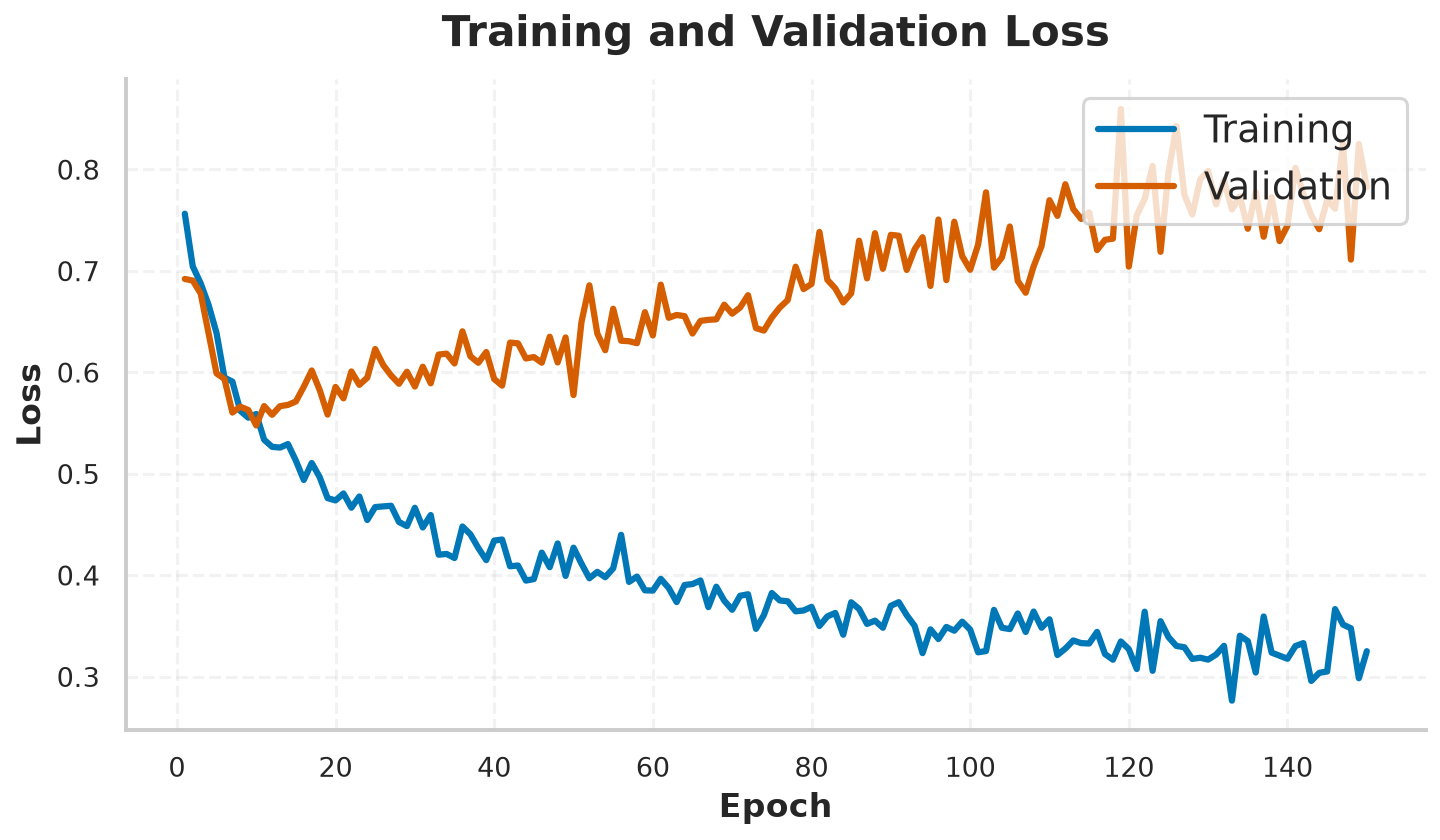

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assumes you recorded epoch_loss and test_loss.item() in these lists each epoch.
# For example: loss_train.append(epoch_loss), loss_val.append(test_loss.item())
loss_data = pd.DataFrame({
    "Epoch": list(range(1, len(loss_train) + 1)) * 2,
    "Loss": loss_train + loss_val,
    "Dataset": (
        ["Training"] * len(loss_train)
        + ["Validation"] * len(loss_val)
    ),
})

sns.set_theme(
    style="whitegrid",
    context="talk",
    font_scale=1.1,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.lineplot(
    data=loss_data,
    x="Epoch",
    y="Loss",
    hue="Dataset",
    hue_order=["Training", "Validation"],
    palette={"Training": "#0077B6", "Validation": "#D55E00"},
    linewidth=3,
    ax=ax,
)

ax.set_title("Training and Validation Loss", pad=16, fontsize=20)
ax.set_xlabel("Epoch", fontsize=16)
ax.set_ylabel("Loss", fontsize=16)
ax.tick_params(axis="both", labelsize=13)
ax.legend(title=None, frameon=True, loc="upper right")
sns.despine()

fig.tight_layout()
# fig.savefig("loss_curve.pdf", bbox_inches="tight")
# fig.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

def predict_labels(model, X, device, batch_size=512):
    """Run batched inference and return CPU predictions."""
    model.eval()
    predictions = []

    with torch.inference_mode():
        for batch in X.split(batch_size):
            logits = model(batch.to(device))
            predictions.append((torch.sigmoid(logits) >= 0.5).long().cpu().view(-1))

    return torch.cat(predictions).numpy()


y_true_rep = y_val_rep.cpu().numpy().reshape(-1)
y_true_relax = y_val_relax.cpu().numpy().reshape(-1)

y_pred_rep = predict_labels(protein_dna_bind_classifier, X_val_rep, device)
y_pred_relax = predict_labels(protein_dna_bind_classifier, X_val_relax, device)

# Confusion matrices use rows=true labels and columns=predicted labels.
labels = [0, 1]
cm_rep = confusion_matrix(y_true_rep, y_pred_rep, labels=labels)
cm_relax = confusion_matrix(y_true_relax, y_pred_relax, labels=labels)

sns.set_theme(
    style="white",
    context="talk",
    font_scale=0.95,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "figure.facecolor": "white",
    },
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=180)

for ax, cm, title in zip(
    axes,
    [cm_rep, cm_relax],
    ["Rep", "Relaxase"],
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        linewidths=1,
        linecolor="white",
        xticklabels=["Negative (0)", "Positive (1)"],
        yticklabels=["Negative (0)", "Positive (1)"],
        annot_kws={"size": 17, "weight": "bold"},
        ax=ax,
    )
    ax.set_title(title, pad=14, fontsize=17)
    ax.set_xlabel("Predicted Label", labelpad=10)
    ax.set_ylabel("True Label", labelpad=10)
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Confusion Matrices", fontsize=21, fontweight="bold", y=1.02)
fig.tight_layout()
# fig.savefig("validation_confusion_matrices.pdf", bbox_inches="tight")
# fig.savefig("validation_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# Overall metrics across both validation sets.
y_true_all = np.concatenate([y_true_rep, y_true_relax])
y_pred_all = np.concatenate([y_pred_rep, y_pred_relax])

overall_accuracy = accuracy_score(y_true_all, y_pred_all)
overall_f1 = f1_score(y_true_all, y_pred_all, zero_division=0)

print(f"Overall validation accuracy: {overall_accuracy:.4f} ({overall_accuracy:.1%})")
print(f"Overall validation F1-score:  {overall_f1:.4f}")

TypeError: BinaryClassifierTwoHeadNN.forward() missing 1 required positional argument: 'dna_input'

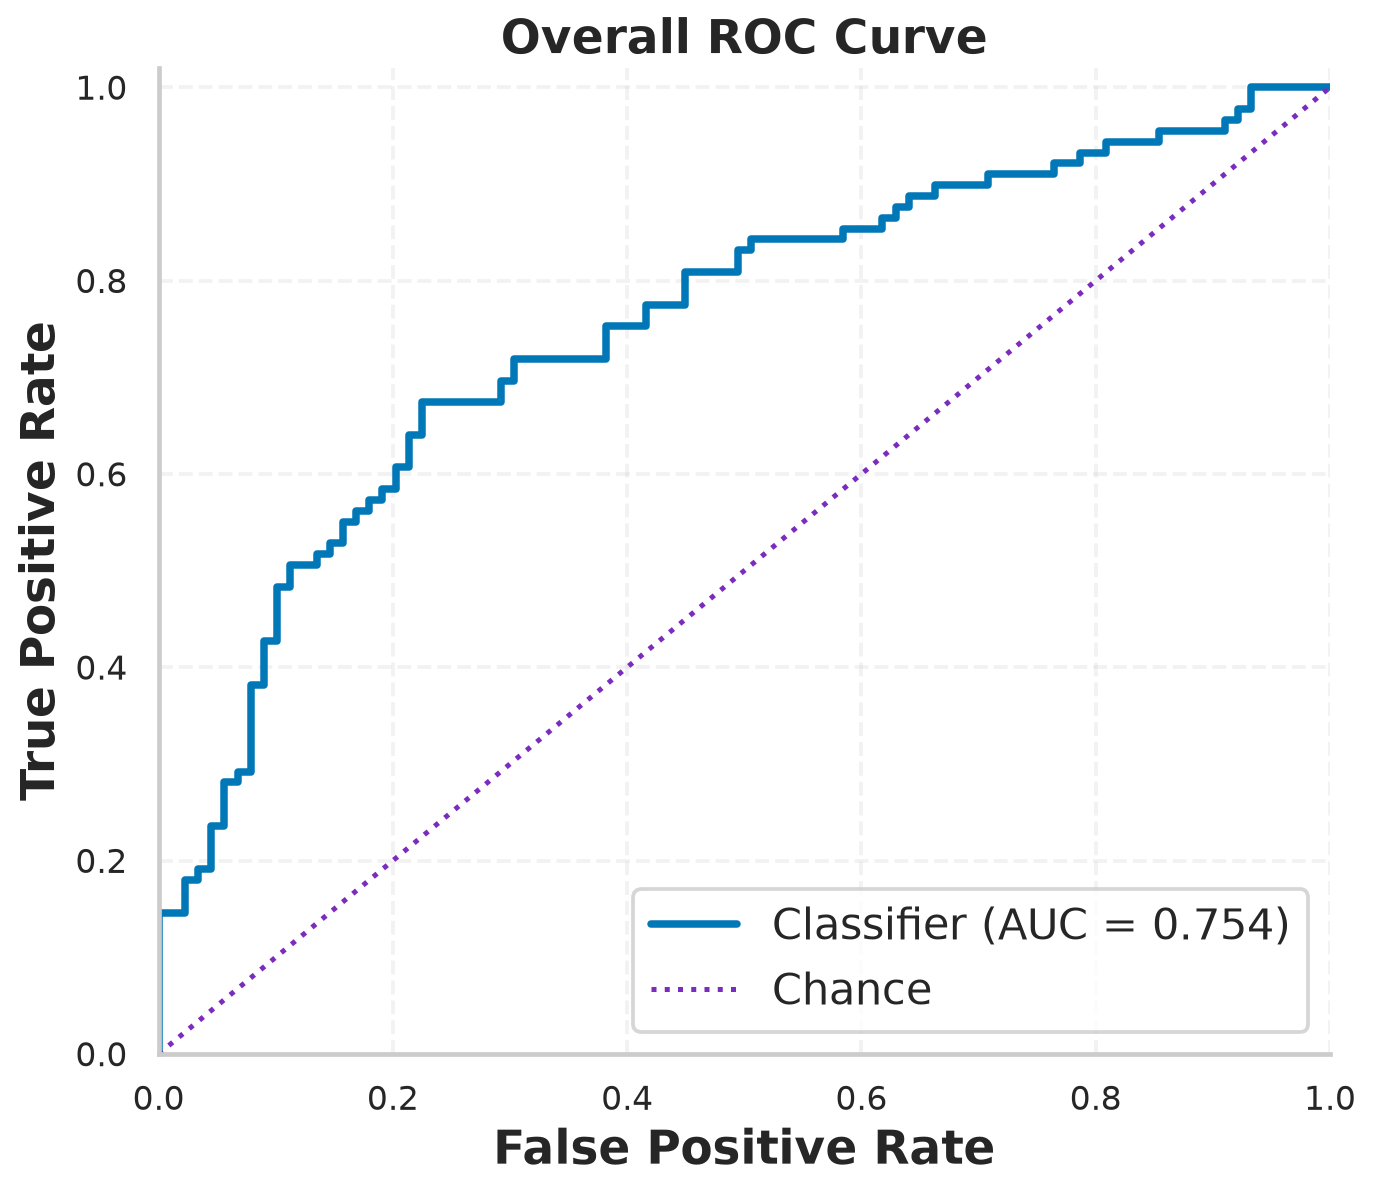

Overall validation ROC AUC: 0.7538


In [116]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

# Combine rep and relaxase validation data.
X_val = torch.cat((X_val_rep, X_val_relax), dim=0)
y_val = torch.cat((y_val_rep, y_val_relax), dim=0).cpu().numpy().ravel()

# Get predicted probabilities for the positive class.
protein_dna_bind_classifier.eval()
probability_parts = []

with torch.inference_mode():
    for batch in X_val.split(512):
        logits = protein_dna_bind_classifier(batch.to(device))
        probability_parts.append(torch.sigmoid(logits).cpu().view(-1))

y_score = torch.cat(probability_parts).numpy()

fpr, tpr, _ = roc_curve(y_val, y_score)
roc_auc = roc_auc_score(y_val, y_score)

sns.set_theme(
    style="whitegrid",
    context="talk",
    font_scale=1.05,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

fig, ax = plt.subplots(figsize=(8, 7), dpi=180)

ax.plot(
    fpr,
    tpr,
    color="#0077B6",
    linewidth=3,
    label=f"Classifier (AUC = {roc_auc:.3f})",
)
ax.plot(
    [0, 1],
    [0, 1],
    color="#7B2CBF",
    linestyle=":",
    linewidth=2,
    label="Chance",
)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1.02),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Overall ROC Curve",
)
ax.legend(loc="lower right", frameon=True)
ax.tick_params(axis="both", labelsize=13)
sns.despine()
fig.tight_layout()

# fig.savefig("overall_validation_roc.pdf", bbox_inches="tight")
# fig.savefig("overall_validation_roc.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Overall validation ROC AUC: {roc_auc:.4f}")

In [34]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Combine validation sets.
X_val = torch.cat((X_val_rep, X_val_relax), dim=0)
y_val = torch.cat((y_val_rep, y_val_relax), dim=0)

# Convert tensors to NumPy arrays for scikit-learn.
X_train_np = X_train.detach().cpu().numpy()
y_train_np = y_train.detach().cpu().numpy().ravel()
X_val_np = X_val.detach().cpu().numpy()
y_val_np = y_val.detach().cpu().numpy().ravel()

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced", random_state=3242),
)

svm.fit(X_train_np, y_train_np)
y_pred = svm.predict(X_val_np)

print(f"SVM overall validation accuracy: {accuracy_score(y_val_np, y_pred):.4f}")

SVM overall validation accuracy: 0.7584


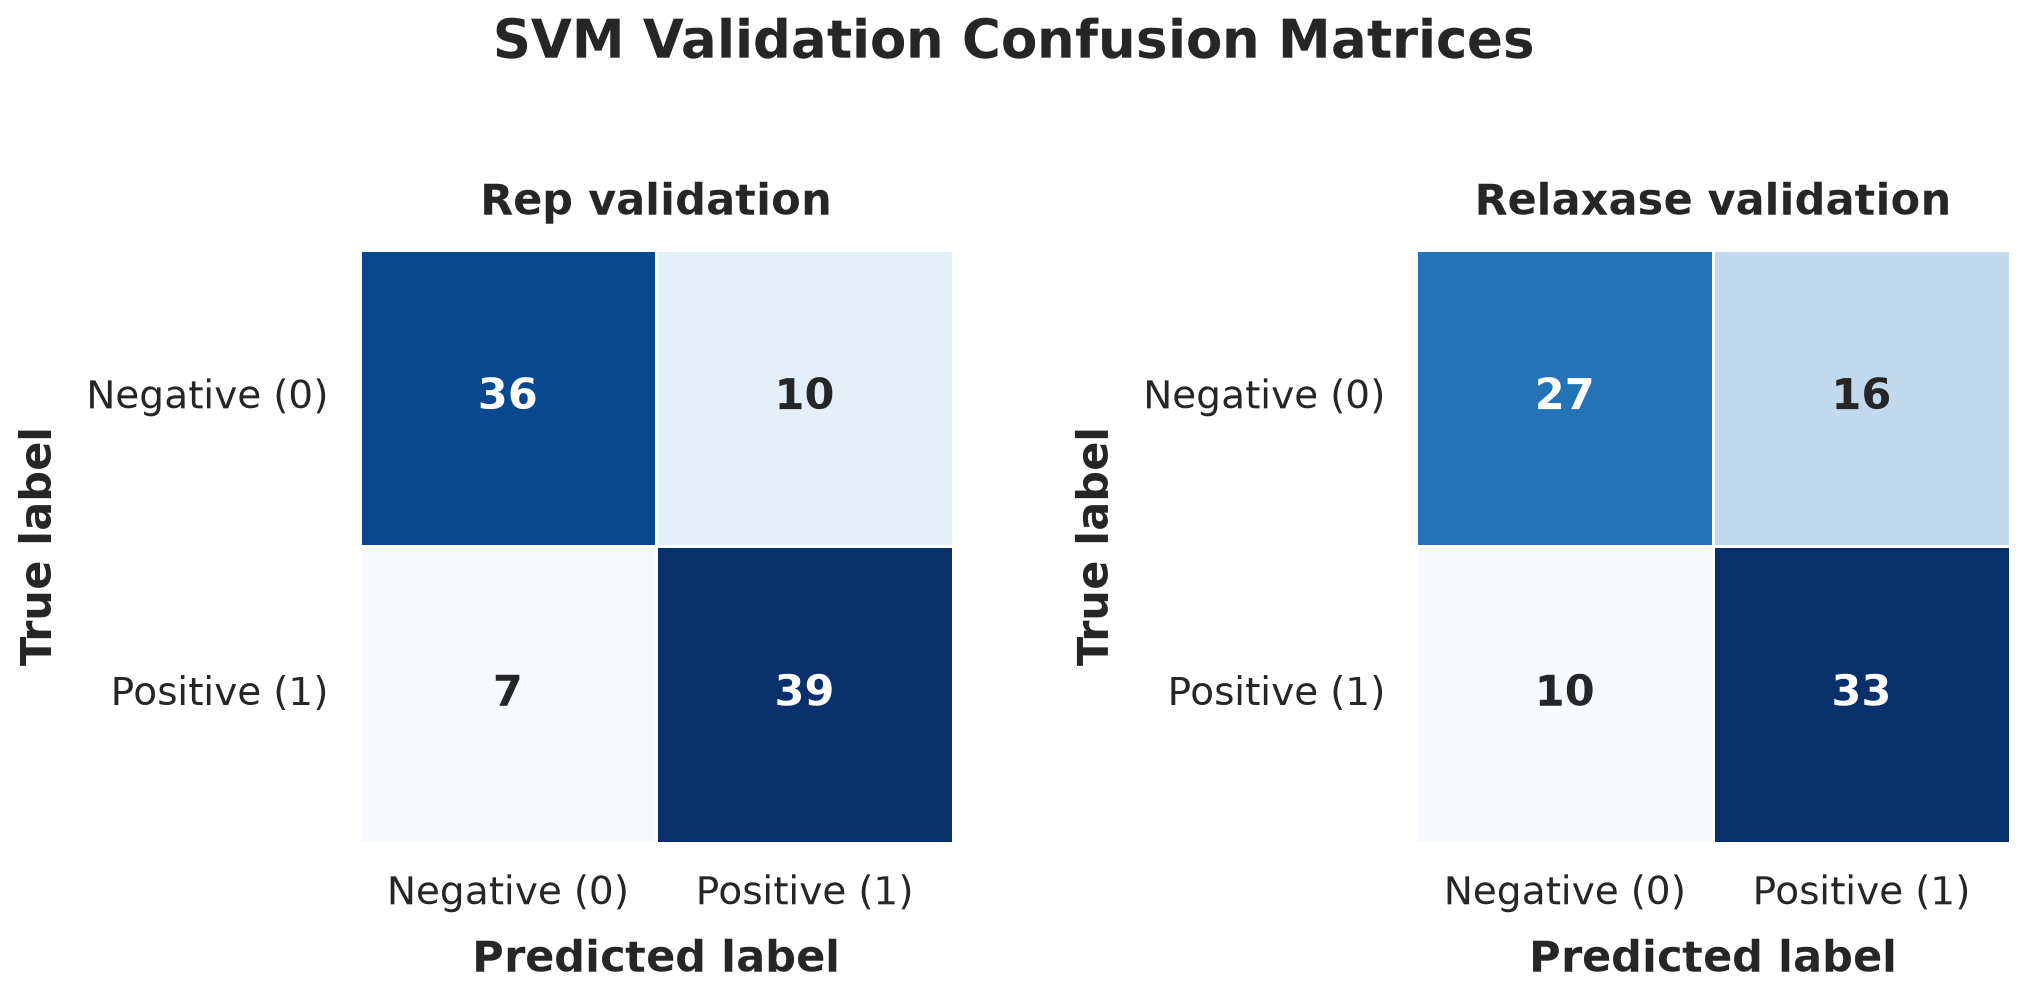

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Convert each validation set to NumPy and predict separately.
X_val_rep_np = X_val_rep.detach().cpu().numpy()
y_val_rep_np = y_val_rep.detach().cpu().numpy().ravel()
y_pred_rep = svm.predict(X_val_rep_np)

X_val_relax_np = X_val_relax.detach().cpu().numpy()
y_val_relax_np = y_val_relax.detach().cpu().numpy().ravel()
y_pred_relax = svm.predict(X_val_relax_np)

labels = [0, 1]
cm_rep = confusion_matrix(y_val_rep_np, y_pred_rep, labels=labels)
cm_relax = confusion_matrix(y_val_relax_np, y_pred_relax, labels=labels)

sns.set_theme(
    style="white",
    context="talk",
    font_scale=0.95,
    rc={"axes.titleweight": "bold", "axes.labelweight": "bold"},
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=180)

for ax, cm, title in zip(
    axes,
    [cm_rep, cm_relax],
    ["Rep validation", "Relaxase validation"],
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        linewidths=1,
        linecolor="white",
        xticklabels=["Negative (0)", "Positive (1)"],
        yticklabels=["Negative (0)", "Positive (1)"],
        annot_kws={"size": 17, "weight": "bold"},
        ax=ax,
    )
    ax.set_title(title, pad=14, fontsize=17)
    ax.set_xlabel("Predicted label", labelpad=10)
    ax.set_ylabel("True label", labelpad=10)
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("SVM Validation Confusion Matrices", fontsize=21, fontweight="bold", y=1.02)
fig.tight_layout()
# fig.savefig("svm_validation_confusion_matrices.pdf", bbox_inches="tight")
# fig.savefig("svm_validation_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

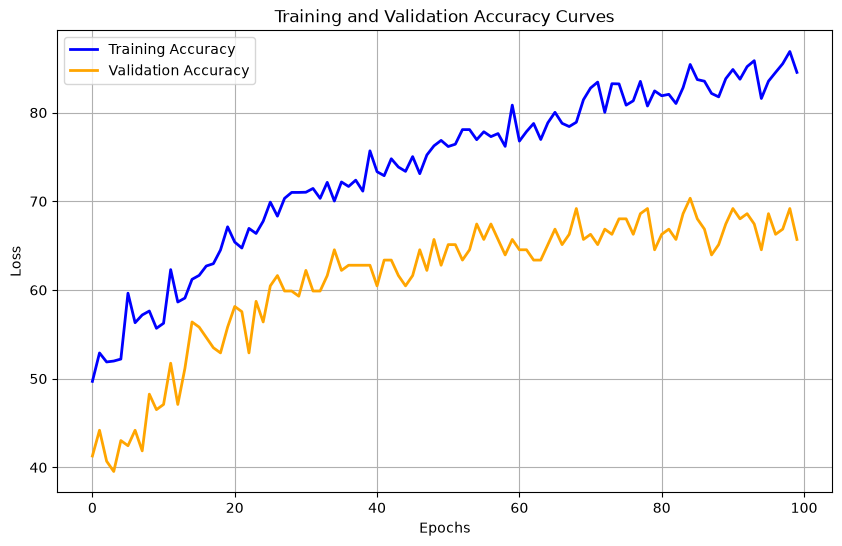

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()